# Home exercise: Ask the Intern
**CPS3235 · Topic 0**

`student_ai_tutor.csv` is a small **synthetic** dataset about students, whether they used an AI tutor, their weekly study hours and their exam mark (pass mark 45).

**Part A: ask the intern (10 min).** Upload the CSV to an LLM of your choice and ask:
> I've attached a dataset of university students (student_ai_tutor.csv). What is the single most interesting finding? Answer in 3-4 sentences.

Copy its answer into the cell below. Note which tool and model you used.

*LLM used:* GPT-5.6 Sol (Medium thinking level, Web interface)

*Its answer:* The most interesting finding is a clear Simpson’s paradox: students who used the AI tutor scored about 6 marks higher overall (60.2 vs 54.2). But within every individual unit, AI-tutor users actually scored lower, by roughly 4–7 marks. The reversal happens because AI-tutor use is much more common in the higher-scoring first-year units (CPS1001/1002), so the overall average is misleading.

**Part B: check the intern's work.** Use pandas. Don't ask the LLM to do Part B for you.

1. Load the data. Check `dtypes`. Is every column the type you expect? Why not?
2. Are there duplicate rows?
3. How many different ways is "yes" written in `used_ai_tutor`? Standardise it.
4. Look at the distribution of `weekly_study_hours`. What's going on at the top end? Decide how to handle it, and **write down your assumptions**.
5. What should you do with `ABS` in `exam_mark`?
6. Recompute the LLM's headline finding on your clean data. Does it hold?
7. Look closely at `unit_code`. Is there a variable hiding in it? Recompute your answer to (6) **within** each group.
8. Is "more study hours → lower marks" true? Check it the same way.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw = pd.read_csv("student_ai_tutor.csv")
raw.head()

,student_id,unit_code,used_ai_tutor,weekly_study_hours,exam_mark
0,S10117,CPS3101,Yes,9.8,45
1,S10283,CPS3102,NaN,9.8,45
2,S10135,CPS1001,No,3.0,67
3,S10024,CPS3102,no,8.9,56
4,S10222,CPS1002,Yes,4.4,50


student_id                str
unit_code                 str
used_ai_tutor             str
weekly_study_hours    float64
exam_mark                 str
dtype: object 


Duplicate rows present?: True
<StringArray>
['Yes', nan, 'No', 'no', 'Y', 'FALSE', 'n', 'yes ', 'No ', 'yes', 'TRUE']
Length: 11, dtype: str 


<StringArray>
['Yes', nan, 'No', 'no', 'FALSE', 'n', 'No ']
Length: 7, dtype: str 


Mark types:  <StringArray>
['45', '67', '56', '50', '49', '61', '73', '59', '38', '57', '95', '44', '52',
 '64', '58', '33', '81', '66', '83', '63', '47', '51', '76', '77', '39', '37',
 '53', '82', '35', '62', '46', '55', '60', '34', '54', '40', '65', '71', '68',
 '72', '43', '42', '70', '36', '48', '75', '69', '79', '29', '88', '80', '74',
 '78', '87', '22', '84', '31']
Length: 57, dtype: str
[ True False]
   used_ai_tutor  exam_mark
0          False  53.710345
1           True  60.402778
<StringArray>
['CPS3101', 'CPS1001', 'CPS3102', 'CPS1002']
Length: 4, dtype: str
  unit_group  used_ai_tutor 

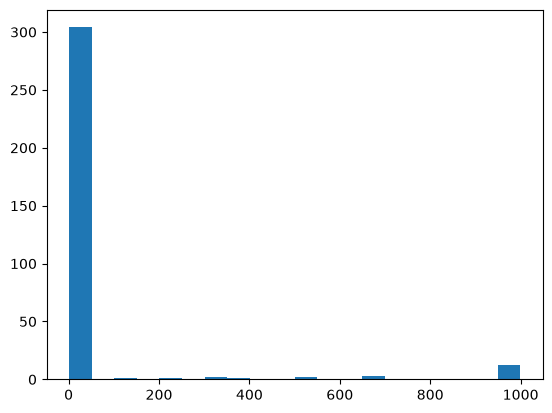

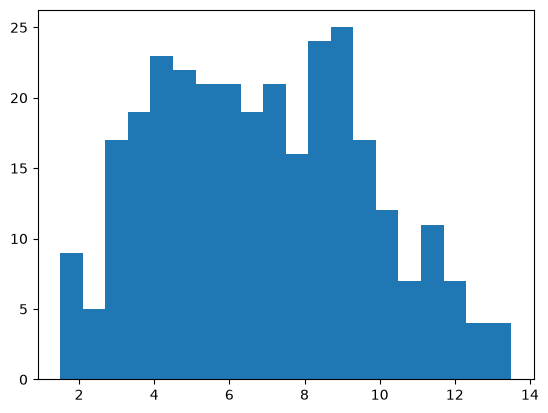

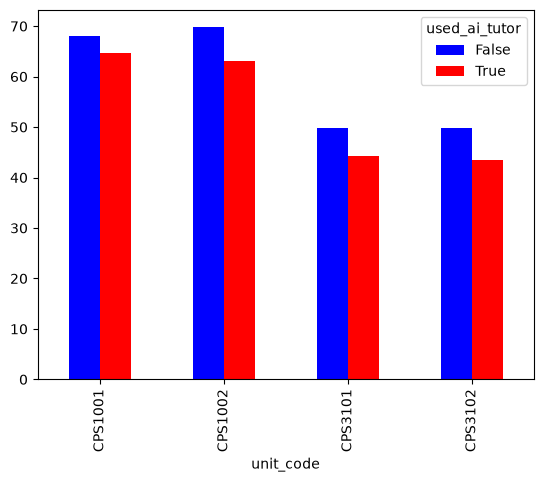

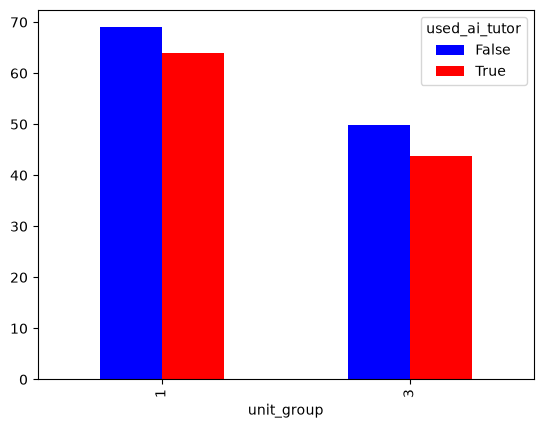

<Figure size 640x480 with 0 Axes>

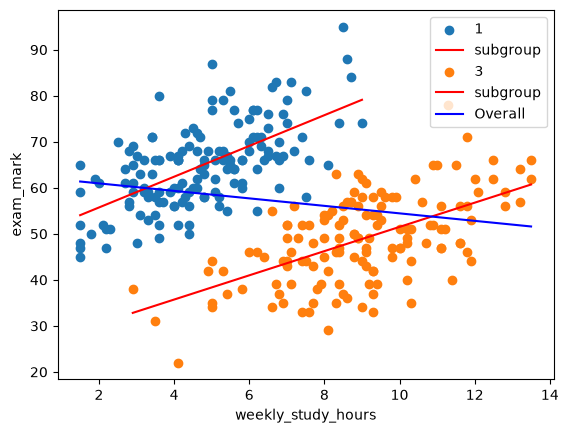

In [19]:
# your work here
# 1 
raw_data = pd.read_csv("student_ai_tutor.csv")
print(raw_data.dtypes, "\n\n")
'''
student_id                str
unit_code                 str 
used_ai_tutor             str -> should be bool
weekly_study_hours    float64 
exam_mark                 str -> should be float64 
'''

#2 ======================================

clean_data = raw_data.copy()

dupcheck = clean_data.duplicated().any() # any returns true if an item in an iterable is true
print("Duplicate rows present?:", dupcheck)

#3 ============================================
yes_types = clean_data['used_ai_tutor'].unique()
print(yes_types, "\n\n")

clean_data['used_ai_tutor'] = clean_data['used_ai_tutor'].replace(['Y', 'yes ', 'yes', 'TRUE'], 'Yes')

yes_types = clean_data['used_ai_tutor'].unique()
print(yes_types, "\n\n")


# 4 ==============================================
# first see the distribution
plt.figure()
plt.hist(clean_data['weekly_study_hours'], bins = 20)


# hours in a week = 168, so all values above that should be considered as incorrect automatically 
# From those, then filter those which ignore sleeping and eating AT LEAST 7 hours a day, so 7 x 7 = 49, 168-49 = 119 threshold

# I will therefore handle the top end by setting a threshold for realistic values. 
# My assumption is that everyone has 7 unusable hours for studying during the day allocated for sleeping, eating, and human activities.


unrealistic_hrs = clean_data[clean_data['weekly_study_hours'] > 119].index
clean_data = clean_data.drop(unrealistic_hrs)
clean_data = clean_data.dropna(subset=['weekly_study_hours']) # remove missing values  

plt.figure()
plt.hist(clean_data['weekly_study_hours'], bins =20)

# 5 ====================================
# without the exam mark, the study becomes abit useless, so remove values without ABS 
abs = clean_data[clean_data['exam_mark'] == 'ABS'].index
clean_data = clean_data.drop(abs)
# verify
mark_types = clean_data['exam_mark'].unique()
print("Mark types: ", mark_types)

# 6 ======================================
# First clean the rest of the data

## fix the types 
clean_data['exam_mark'] = clean_data['exam_mark'].astype(float)

clean_data['used_ai_tutor'] = clean_data['used_ai_tutor'].replace(['no', 'FALSE', 'n', 'No '], 'No')
clean_data = clean_data.dropna(subset = ['used_ai_tutor'])
clean_data['used_ai_tutor'] = clean_data['used_ai_tutor'].map({'Yes': True, 'No': False})
clean_data['used_ai_tutor'] = clean_data['used_ai_tutor'].astype(bool)
print(clean_data['used_ai_tutor'].unique())


## Now investigate the claim. 
# RTP:
# students who used the AI tutor scored about 6 marks higher overall (60.2 vs 54.2)
# within every individual unit, AI-tutor users actually scored lower, by roughly 4–7 marks


print(clean_data.groupby("used_ai_tutor", as_index=False)["exam_mark"].mean())

clean_data.pivot_table(index="unit_code", columns="used_ai_tutor", values="exam_mark", aggfunc = "mean").plot.bar(color=["blue", "red"])

# both hold

# 7 =================================
print(clean_data['unit_code'].unique())
## the unit codes either start with a 3 or a 1; i.e they can be split even further. Assumption: The prefix of the unit code matters. 

clean_data['unit_group'] = clean_data['unit_code'].str[3] ## C P S X -> 3rd location via 0 indexing 

# redo 6 
print(clean_data.groupby(['unit_group', 'used_ai_tutor'], as_index=False)["exam_mark"].mean())

clean_data.pivot_table(index="unit_group", columns="used_ai_tutor", values="exam_mark", aggfunc = "mean").plot.bar(color=["blue", "red"])

# 8 =================================
# We need to see : do higher study hours average lower marks? 

# Overall
print(clean_data.groupby("weekly_study_hours", as_index=False)["exam_mark"].mean())

plt.figure()
clean_data.plot.scatter(x = "weekly_study_hours",y = "exam_mark")

# then colour the scatter plot to show the indivisual unit groups 
for group, data in clean_data.groupby("unit_group"):
    plt.scatter(data["weekly_study_hours"], data["exam_mark"], label=group)

    # best fit lines for each group 
    b, a = np.polyfit(data["weekly_study_hours"], data["exam_mark"], deg=1) #deg = polynomial of degree 1 (linear)
    xseq = np.linspace(data["weekly_study_hours"].min(), data["weekly_study_hours"].max(), 100)
    plt.plot(xseq, a+b *xseq, color = "red", label = "subgroup")

# Best fit line for overall (to show Simpson's paradox)
b, a = np.polyfit(clean_data["weekly_study_hours"], clean_data["exam_mark"], deg=1) #deg = polynomial of degree 1 (linear)
xseq = np.linspace(clean_data["weekly_study_hours"].min(), clean_data["weekly_study_hours"].max(), 100)
plt.plot(xseq, a+b *xseq, color = "blue", label = "Overall")

plt.legend()
plt.show()




**Part C: reflect (5-10 lines).**
- Was the LLM's finding *wrong*, *misleading* or *right*? Be precise.
- Which of your cleaning decisions would you need to confirm with whoever collected the data?
- Can this dataset tell you whether AI tutors **cause** better or worse marks? Why or why not?
- What would you have to ask the LLM to get a better answer? Try it, and report what happened.

The LLM's finding was essentially spot on. All claims it made were true according to the recomputation of its findings. 

Regarding cleaning decisions, a few things would need to be verified, mainly the verification that the first number in the unit code is an actual variable that can be split on, whether the excessively high weekly study hours were in fact errors, and that marks were not deducted for using AI within any study unit in the dataset

This Dataset can give insight on correlation, but not causation. In reality, a multitude of variables can be at play when affecting the overall outcome of marks. 

Since the LLM's answer was correct, I do not feel that much could be added to the prompt to get a better answer. Potentially I could ask the LLM to clean data before analysing it, however that would add more verification from my end, as I would ontop of verifying its claims, verify that it cleaned the data appropriately. 
